# Credit Risk Portfolio Analytics — reproducible walkthrough

This notebook runs the project's pipeline from the `src/` modules and shows every output the assignment asks for: ingestion and data quality, portfolio analytics with insights, the two default models with AUC / KS / Gini and SHAP, and the anomaly feature that is embedded in the dashboard.

All numbers are computed live from `data/raw/`. The dashboard is a separate Streamlit app: `streamlit run app/dashboard.py`.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from IPython.display import Markdown, Image, display

## 1. Data ingestion and data quality

Load the five tables, validate keys and relationships, clean, aggregate one-to-many tables to their join grain, and join at loan level. Row counts are asserted at every join.

In [2]:
from src.ingestion import load_raw_tables, validate_tables
tables = load_raw_tables()
findings = validate_tables(tables)
print("Row counts:", findings["row_counts"])
print("Orphan foreign keys:", {k: v["orphan_rows"] for k, v in findings["foreign_keys"].items()})
print("Coverage:", findings["coverage"])

Row counts: {'customers': 10000, 'loan_accounts': 14685, 'bureau_credit': 22979, 'repayment_history': 176220, 'collections_events': 8635}
Orphan foreign keys: {'loan_accounts.customer_id -> customers': 0, 'bureau_credit.customer_id -> customers': 0, 'repayment_history.account_id -> loan_accounts': 0, 'collections_events.account_id -> loan_accounts': 0}
Coverage: {'customers_without_loans': 0, 'customers_without_bureau': 1008, 'loans_without_repayment': 0, 'loans_with_collections': 4278}


In [3]:
from src.build_dataset import build
df, summary = build(write=True)   # also writes data/processed/* and reports/data_quality_report.md
pd.DataFrame([summary["reconciliation"]]).T.rename(columns={0: "rows"})

,rows
loan_accounts_start,14685
after_customers,14685
after_bureau,14685
after_repayment,14685
after_collections,14685
after_bureau_time_filtered,14685
customers_in_final,10000
defaults_in_final,2364
defaults_in_raw,2364


In [4]:
issues = pd.DataFrame(summary["issue_log"])[["table", "field", "rows_affected", "found", "handled"]]
issues

,table,field,rows_affected,found,handled
0,customers,gender,600,600 rows coded 'M'/'F' alongside 'Male'/'Female',"Mapped M→Male, F→Female"
1,customers,years_employed,500,500 missing (5.0%),Kept as NaN + added missing flag; model impute...
2,customers,num_dependents,500,500 missing (5.0%),Kept as NaN + added missing flag; model impute...
3,customers,years_at_residence,500,500 missing (5.0%),Kept as NaN + added missing flag; model impute...
4,customers,annual_income,494,All 494 'Unemployed' customers have annual_inc...,Kept as supplied; raised as open question Q2 i...
5,loan_accounts,interest_rate_pct,294,"294 missing (2.0%), spread evenly across loan ...",Raw column kept with NaN + missing flag; `inte...
6,loan_accounts,collateral_flag,0,0 rows inconsistent with loan_type (Mortgage/A...,No change needed
7,loan_accounts,origination_date vs customers.customer_since,7293,7293 loans (49.7%) originated before the custo...,Both dates kept; a flag column records the inc...
8,bureau_credit,days_past_due,689,"689 missing (3.0%), spread evenly across statuses",Kept as NaN; aggregations skip NaN and a per-c...
9,bureau_credit,date_closed,11243,"11243 nulls, all on Active lines (structural, ...",Kept as NaT


In [5]:
df.shape, df["target_default"].mean(), df.groupby("customer_id")["target_default"].max().mean()

((14685, 92), np.float64(0.1609805924412666), np.float64(0.2159))

## 2. Portfolio analytics

Profiles across income, employment type, region, age and loan type; cross-dimensional cuts; vintage trend; five insights.

In [6]:
from src import analytics
analytics.run()
for dim in ["loan_type", "income_band", "employment_type", "region", "age_band"]:
    p = analytics.profile_by(df, dim)
    display(Markdown(f"**By {dim}**"))
    display(p[["loans", "customers", "exposure", "exposure_share", "loan_default_rate", "customer_default_rate", "exposure_weighted_default_rate"]].round(3))

Analytics written to reports/portfolio_findings.md, reports/tables/, reports/figures/


**By loan_type**

,loans,customers,exposure,exposure_share,loan_default_rate,customer_default_rate,exposure_weighted_default_rate
loan_type,,,,,,,
Auto Loan,2832,2626,7.879581e+07,0.131,0.139,0.147,0.141
Business Loan,1484,1431,9.901763e+07,0.165,0.160,0.166,0.166
Credit Card,3721,3388,3.001684e+07,0.050,0.162,0.174,0.161
Mortgage,1432,1387,3.144738e+08,0.523,0.247,0.252,0.263
Personal Loan,5216,4563,7.881549e+07,0.131,0.149,0.165,0.153


**By income_band**

,loans,customers,exposure,exposure_share,loan_default_rate,customer_default_rate,exposure_weighted_default_rate
income_band,,,,,,,
<40k,934,640,3.832992e+07,0.064,0.324,0.400,0.412
40-60k,2281,1556,9.617081e+07,0.160,0.223,0.295,0.281
60-80k,4290,2899,1.771964e+08,0.295,0.166,0.225,0.223
80-100k,4082,2778,1.649560e+08,0.274,0.133,0.184,0.174
100k+,3098,2127,1.244665e+08,0.207,0.095,0.131,0.128


...

,loans,customers,exposure,exposure_share,loan_default_rate,customer_default_rate,exposure_weighted_default_rate
employment_type,,,,,,,
Business Owner,1844,1244,7.351125e+07,0.122,0.136,0.189,0.189
Contract,1563,1076,6.159217e+07,0.102,0.173,0.227,0.228
Salaried,7546,5149,3.130173e+08,0.521,0.150,0.204,0.197
Self-Employed,3014,2037,1.233732e+08,0.205,0.153,0.204,0.191
Unemployed,718,494,2.962552e+07,0.049,0.350,0.431,0.461


**By region**

,loans,customers,exposure,exposure_share,loan_default_rate,customer_default_rate,exposure_weighted_default_rate
region,,,,,,,
Central,2314,1579,9.631142e+07,0.160,0.150,0.205,0.191
East,2747,1908,1.082062e+08,0.180,0.160,0.212,0.201
North,3147,2115,1.294322e+08,0.215,0.164,0.216,0.215
South,3600,2420,1.562678e+08,0.260,0.169,0.230,0.229
West,2877,1978,1.109018e+08,0.184,0.158,0.211,0.209


**By age_band**

,loans,customers,exposure,exposure_share,loan_default_rate,customer_default_rate,exposure_weighted_default_rate
age_band,,,,,,,
21-30,3648,2485,1.582222e+08,0.263,0.208,0.276,0.265
31-40,5053,3459,2.031309e+08,0.338,0.167,0.222,0.227
41-50,4113,2794,1.656435e+08,0.276,0.138,0.186,0.173
51-60,1593,1062,6.135694e+07,0.102,0.111,0.157,0.143
61+,278,200,1.276592e+07,0.021,0.072,0.100,0.122


**Income band × employment type — loan default rate (cells with n<30 masked)**

employment_type,Business Owner,Contract,Salaried,Self-Employed,Unemployed
income_band,,,,,
<40k,NaN,35.1,23.9,28.2,41.7
40-60k,18.2,25.8,21.2,20.0,31.0
60-80k,18.7,12.8,16.1,17.6,26.8
80-100k,11.9,13.8,14.1,11.8,NaN
100k+,9.5,10.6,9.0,10.5,NaN


employment_type,Business Owner,Contract,Salaried,Self-Employed,Unemployed
income_band,,,,,
<40k,25,114,314,131,350
40-60k,148,360,1061,515,197
60-80k,486,501,2288,877,138
80-100k,587,362,2214,891,28
100k+,598,226,1669,600,5


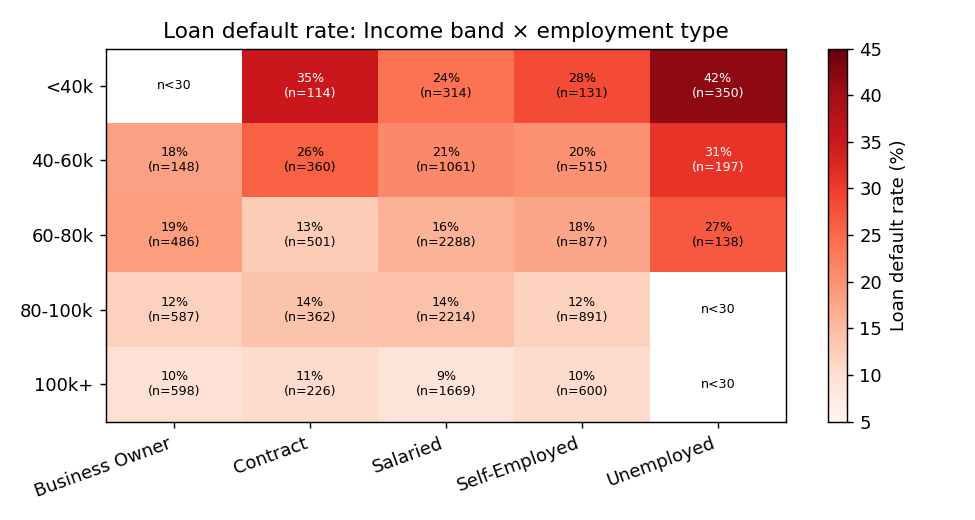

In [7]:
rate, n = analytics.cross_cut(df, "income_band", "employment_type")
display(Markdown("**Income band × employment type — loan default rate (cells with n<30 masked)**"))
display((rate * 100).round(1)); display(n)
Image(filename=str(ROOT / "reports/figures/cross_income_x_employment.png"))

In [8]:
analytics.vintage_trend(df).round(3)

,loans,exposure,loan_default_rate
origination_year,,,
2018,2487,1.004544e+08,0.166
2019,2434,9.799300e+07,0.157
2020,2396,9.931604e+07,0.149
2021,2447,1.039654e+08,0.177
2022,2451,9.858171e+07,0.166
2023,2470,1.008090e+08,0.151


In [9]:
ins = json.load(open(ROOT / "reports/portfolio_metrics.json"))
text = (ROOT / "reports/portfolio_findings.md").read_text()
Markdown(text[text.index("## Insights"):])

## Insights

### 1. Mortgages are half the book's exposure and its highest-default product

Mortgages are 9.8% of loan accounts but 52.3% of exposure (1,432 loans). Their loan-level default rate is 24.7% against 15.2% for all other products combined, and 26.3% of mortgage exposure sits in defaulted loans. The pattern is steepest at low incomes: mortgage borrowers earning under 60k default at 35.1% (n=316, 71m exposure); under 40k the rate is 48.8% but on only 86 loans, so treat that cell as indicative.

**So what:** the portfolio's largest exposure concentration is also its worst-performing one. Collateral limits the loss given default, but a one-in-four default frequency on the biggest tickets dominates expected loss. **Action:** review mortgage affordability criteria (income floors, loan-to-income caps) and consider tighter limits or pricing for sub-60k income mortgage applicants; monitor mortgage exposure share as a concentration metric.

### 2. Default risk falls steadily with income; the lowest band defaults 3.4× as often as the highest

Borrowers earning under 40k are 6.4% of exposure (934 loans) yet 12.5% of defaulted exposure; their default rate is 32.4% versus 9.5% for the 100k+ band (3,098 loans). The gradient is monotonic across all five bands. Affordability explains part of it: the top loan-to-income quintile (LTI > 0.63) defaults at 23.8% against 13.2% for the bottom quintile.

**So what:** income and leverage are the strongest application-stage signals in the data and the low-income band is over-represented in losses relative to its size. **Action:** introduce or tighten loan-to-income limits for sub-60k applicants and route them to enhanced income verification; price the gradient explicitly rather than cross-subsidising.

### 3. 'Unemployed' borrowers default at more than twice the portfolio rate

718 loans (494 customers, 4.9% of exposure) belong to customers recorded as Unemployed. Their loan-level default rate is 35.0% vs 15.1% for everyone else; at customer level 43.1% of unemployed customers have a defaulted loan vs 20.5%. The segment contributes 10.8% of defaulted exposure — more than double its share of the book. Within the income × employment cut, Unemployed is the worst column in every income band where the cell has 30+ loans.

**So what:** a small, clearly identifiable segment carries disproportionate loss. Note every Unemployed customer reports positive income (median ≈ 41k), which is undefined in the data dictionary (open question Q2). **Action:** confirm what 'income' means for this group, require documented income sources, and consider a policy rule (decline or secured-only) rather than relying on the model alone.

### 4. Prior bureau write-offs and thin files identify elevated risk before any repayment is observed

Loans to customers with two or more written-off bureau lines (763 loans) default at 23.2%, against 14.6% with none (8,944 loans) and 17.7% with exactly one. Customers with no bureau file at all (1,462 loans) default at 17.6%, i.e. a thin file is riskier than a clean file. External delinquency adds to this: loans whose customer has a bureau line 30-60 days past due default at 20.6% vs 13.3% when max bureau DPD is ≤ 30.

**So what:** bureau history is usable at application time and separates risk without waiting for internal repayment behaviour. **Action:** add a 'two or more write-offs' hard stop or manual-review rule and treat no-bureau-file applicants as a distinct policy segment (e.g. lower initial limits).

### 5. Borrowers aged 21-30 are a quarter of exposure and default at almost three times the rate of over-60s

The 21-30 band is 3,648 loans and 26.3% of exposure, with a default rate of 20.8% vs 13.8% for 41-50 and 7.2% for 61+ (278 loans). Age interacts with income: young borrowers under 40k default at 34.0% (n=373) while young borrowers over 100k default at 11.1% (n=486) — the age effect is mostly an income-and-leverage effect.

**So what:** young borrowers are a growth segment but their loss rate is concentrated where income is also low. **Action:** segment limits by age × income rather than age alone (avoiding a blunt age rule that would raise fairness concerns) and target early-engagement collections for young, low-income accounts.

### What did *not* show up

- Region is flat: loan-level default rates range only from 15.0% to 16.9%. The only regional pattern is in mortgages (South 27.3% vs Central 21.3%), and the regional mortgage cells are 170-390 loans, so this is suggestive rather than conclusive.
- Disbursal channel and city tier show differences of under two percentage points.
- The number of loans a customer holds (1-3) barely moves the default rate (15.7% → 16.8%).

## 3. Credit default prediction

Customer-grouped 80/20 split (no customer on both sides), out-of-time check on the 2023 vintage, logistic regression baseline and LightGBM, SHAP explanations, sensitivity runs. Gini = 2·AUC − 1, KS = max(TPR − FPR).

In [10]:
from src import modeling
modeling.run()   # trains both models, writes models/, reports/model_evaluation.md, data/processed/scored_loans.parquet
res = json.load(open(ROOT / "reports/model_results.json"))
pd.DataFrame(res["test_metrics"]).T.round(4)

{
  "logistic_regression": {
    "roc_auc": 0.6841517551545686,
    "gini": 0.3683035103091372,
    "ks": 0.27631705046411653,
    "brier": 0.22338078077090084
  },
  "lightgbm": {
    "roc_auc": 0.6839861826072671,
    "gini": 0.36797236521453414,
    "ks": 0.270998192820569,
    "brier": 0.12553567103355165
  }
}


,roc_auc,gini,ks,brier
logistic_regression,0.6842,0.3683,0.2763,0.2234
lightgbm,0.6840,0.3680,0.2710,0.1255


In [11]:
print("Out-of-time (2023 vintage):"); display(pd.DataFrame({k: v for k, v in res["out_of_time_2023"].items() if isinstance(v, dict)}).T.round(4))
print("Sensitivity (LightGBM):"); display(pd.DataFrame(res["sensitivity_lightgbm"]).T.round(4))
print("Observed default rate by risk segment (test):"); display(pd.DataFrame(res["segment_default_rate_test"]).T)

Out-of-time (2023 vintage):


,roc_auc,gini,ks,brier
lightgbm,0.6907,0.3813,0.2987,0.1199
logistic_regression,0.6957,0.3914,0.3117,0.2206


Sensitivity (LightGBM):


,roc_auc,gini,ks,brier
application_only,0.6519,0.3037,0.2456,0.1292
no_bureau,0.6784,0.3568,0.2786,0.1261
no_repayment,0.6629,0.3259,0.2651,0.1279
time_filtered_bureau,0.6828,0.3656,0.2720,0.1256


Observed default rate by risk segment (test):


,loans,default_rate
Low,2057.0,0.112299
Medium,589.0,0.222411
High,302.0,0.364238


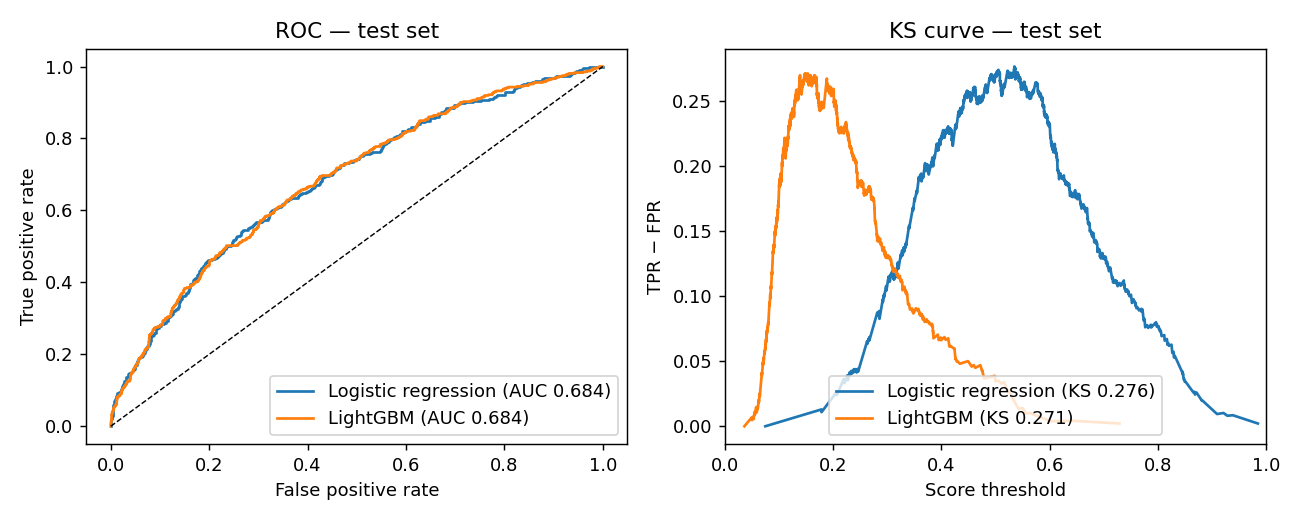

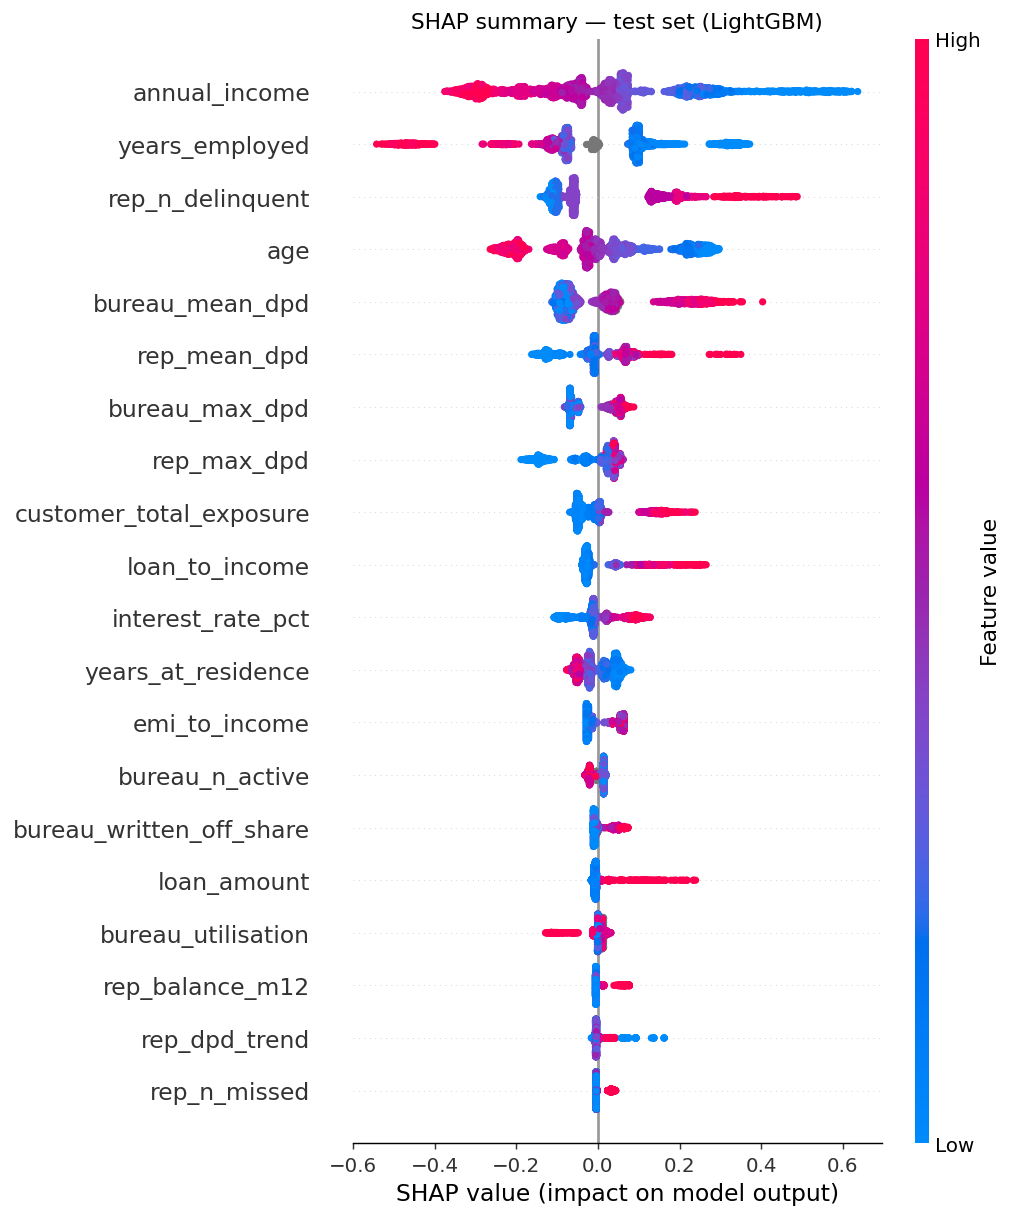

annual_income               0.1668
years_employed              0.1367
rep_n_delinquent            0.1246
age                         0.1188
bureau_mean_dpd             0.0955
rep_mean_dpd                0.0601
bureau_max_dpd              0.0543
rep_max_dpd                 0.0510
customer_total_exposure     0.0459
loan_to_income              0.0438
interest_rate_pct           0.0432
years_at_residence          0.0373
emi_to_income               0.0306
bureau_n_active             0.0151
bureau_written_off_share    0.0134
Name: mean |SHAP| (test), dtype: float64

In [12]:
display(Image(filename=str(ROOT / "reports/figures/model_roc_ks.png")))
display(Image(filename=str(ROOT / "reports/figures/model_shap_summary.png")))
pd.Series(res["top_features_shap"], name="mean |SHAP| (test)")

In [13]:
Markdown((ROOT / "reports/model_evaluation_notes.md").read_text())

# Model Evaluation Notes — reading the results

These notes interpret the numbers in `model_evaluation.md` / `model_results.json` (seeded run, `RANDOM_SEED = 42`). If the pipeline is re-run in a different environment the figures may move in the third decimal; the conclusions below do not depend on that.

## 1. How much signal is there?

Both models land at a test ROC-AUC of about 0.68 (Gini ≈ 0.37, KS ≈ 0.27), and the out-of-time check on the 2023 vintage gives essentially the same picture (AUC 0.69-0.70). That is a usable but modest separation: the top-decile "High" segment defaults at 36% against an 11% rate in "Low", so the score ranks risk three-to-one across segments, but it is nowhere near strong enough to make automated decline decisions. The data dictionary describes the synthetic signal as "clear but not trivial", and that is what we see.

Three things support that the result is genuine rather than an artefact:

- The train/test gap is small for both models (LightGBM 0.71 → 0.68; logistic 0.69 → 0.68), so neither is over-fitting the training customers.
- The customer-grouped split means no borrower's loans are split across folds, and the out-of-time vintage test is consistent with the random split.
- The sensitivity runs behave as a credit analyst would expect: removing repayment features costs ~0.02 AUC, removing bureau features ~0.006, and an application-only model drops to 0.65. Engineered behavioural and bureau features therefore add real, if modest, lift over raw application fields.

## 2. Logistic regression vs LightGBM

On discrimination the two are tied (0.6842 vs 0.6840 AUC; KS 0.276 vs 0.271). The cross-validation grid tells the story: LightGBM's best configuration was the shallowest one tried (3 leaves, 300 trees), and every deeper setting scored worse. The relationships in this data are close to additive and monotonic — income, employment tenure, age, delinquency counts and bureau DPD all move risk in one direction — which is exactly the situation where a well-regularised logistic model matches a gradient-boosted one.

The differences are elsewhere:

| Consideration | Logistic regression | LightGBM |
|---|---|---|
| Discrimination (AUC / KS / Gini) | 0.684 / 0.276 / 0.368 | 0.684 / 0.271 / 0.368 |
| Probability calibration | Not calibrated as fitted (class-weighted; Brier 0.22) — would need a Platt/isotonic step | Close to calibrated out of the box (Brier 0.13; decile table tracks the diagonal) |
| Missing data | Needs explicit imputation; "no bureau file" collapses to median values + flag | Handles NaN natively; thin-file pattern learned directly |
| Explainability | Global: standardised coefficients. Per-loan: coefficient × value, fully transparent | Per-loan SHAP values (exact for trees); global importance by gain and mean |SHAP| |
| Governance familiarity | Standard scorecard form; easiest to validate and document | Widely accepted but requires more validation effort |

## 3. Recommendation

**For the dashboard in this assignment: LightGBM.** The account view needs a probability a risk manager can read as "roughly 1-in-4" and a per-loan driver breakdown; LightGBM delivers both without an extra calibration layer, and its SHAP values are exact. Risk segments (Low / Medium / High) are cut on its score.

**For a production scorecard: start with the logistic model, keep LightGBM as a challenger.** Given no measurable accuracy advantage, the simpler model wins on validation cost, auditability and regulatory familiarity. A calibration step would be added before deployment. LightGBM should be retained as a monitored challenger; if future data (longer repayment history, time-stamped bureau pulls) introduces non-linear or interaction effects, it will show up as a widening gap in the quarterly performance comparison.

**Either way, the score is decision support, not a decision.** At the High cut-off, 36% precision means almost two of every three flagged accounts would not default; at the Medium cut-off the model catches half of defaults by flagging 30% of the book. Those trade-offs must be set by the risk team against collections capacity and tolerance for false positives, and the chosen threshold must be documented with the reasons.

## 4. What the drivers say

The top features by mean |SHAP| are annual income, years employed, the count of delinquent months in the first year, age and mean bureau DPD. This agrees with the portfolio analytics (income gradient, unemployed segment, bureau write-offs/DPD) and with the logistic coefficients (`annual_income` −0.23, `years_employed` −0.18, `employment_type_Unemployed` +0.17, `age` −0.17, `bureau_mean_dpd` +0.13 on standardised inputs). The agreement between a linear model, a tree model and simple cross-tabs is reassuring: the drivers are features of the data, not of one algorithm.

## 5. Caveats carried into the recommendation

- Age is a model input and is also a protected characteristic in many jurisdictions. It is the fourth-strongest driver. The disparity table shows younger borrowers are flagged High roughly four times as often as 41-50s — consistent with their observed default rate, but the compliance team must decide whether age may be used at all (assumption A9). A version without `age` should be validated before any production use.
- The bureau snapshot is not time-stamped (A3). The time-filtered sensitivity model loses only 0.001 AUC, which suggests the leakage exposure is small, but it cannot be ruled out from this data.
- `target_default` timing is assumed (A1-A2). If defaults can occur inside the 12-month window, repayment features partially describe the outcome rather than predict it.


### Post-deployment monitoring (proposed, not implemented here)

In [14]:
text = (ROOT / "reports/model_evaluation.md").read_text()
Markdown(text[text.index("## Post-deployment monitoring"):])

## Post-deployment monitoring (proposed — not implemented here)

Once live, the score should be monitored monthly. **PSI** on the predicted-PD distribution (training population vs the latest scored month, 10 score bins) and **CSI** on each input feature's distribution (same bins) detect population drift; PSI/CSI below 0.10 is stable, 0.10-0.25 warrants investigation, above 0.25 triggers escalation to the model-risk team. Input-distribution checks should include missing-value rates (a jump in `interest_rate_pct_missing` or in customers with no bureau file would signal an upstream feed problem). When outcomes mature — here, once each loan's post-window default status is known — observed default rate by score decile, AUC, KS and Gini are recomputed quarterly and compared with the test-set benchmarks (AUC 0.684, KS 0.271); a drop of more than 0.05 AUC or a decile ranking inversion is an alert. Retraining is proposed annually, or earlier if PSI > 0.25, AUC falls below the alert level, or a material product/policy change occurs. Any retrained model goes through the same held-out and out-of-time validation, a fairness check, independent model-validation sign-off and a documented rollback plan (previous model kept deployable) before it replaces the production scorer. **In this assignment** only the one-off validation above exists; no monitoring job is implemented because there is no post-deployment data to monitor.

## 4. Embedded AI feature — anomaly detection

The same rules run inside the dashboard's *Anomalies* page with a human review queue. Here they are run on the full book.

In [15]:
from src.anomaly import RULES, detect_anomalies, summarise_flags
flags = detect_anomalies(df)
summ = summarise_flags(flags, df)
print(f"{len(summ):,} accounts flagged ({len(summ)/len(df):.1%}); {int((summ.n_flags>=2).sum())} with 2+ rules")
print("Flagged default rate:", round(summ.target_default.mean(), 3), "| unflagged:", round(df[~df.account_id.isin(summ.account_id)].target_default.mean(), 3))
display(pd.DataFrame([{"rule": k, "name": v["name"], "trigger": v["trigger"]} for k, v in RULES.items()]))
flags.head(10)

1,420 accounts flagged (9.7%); 351 with 2+ rules
Flagged default rate: 0.23 | unflagged: 0.154


,rule,name,trigger
0,R1,DPD spike vs own history,mean DPD in months 10-12 is at least 20 days a...
1,R2,Missed payments vs peers,missed-payment count above the peer 95th perce...
2,R3,Underpayment vs peers,paid/due ratio below the peer 5th percentile
3,R4,External stress not visible internally,≥ 2 written-off bureau lines or bureau max DPD...


,account_id,rule,rule_name,measured,threshold,comparison_group,evidence
0,ACC200012,R2,Missed payments vs peers,3.00,2.000,Credit Card | 100k+ (n=774),3 missed months vs peer 95th percentile 2
1,ACC200012,R3,Underpayment vs peers,0.75,0.833,Credit Card | 100k+ (n=774),"paid 1,421 of 1,895 due (75.0%) vs peer 5th pe..."
2,ACC200013,R1,DPD spike vs own history,25.00,20.000,own months 1-9,"mean DPD months 1-9 = 10.7, months 10-12 = 35...."
3,ACC200013,R2,Missed payments vs peers,3.00,2.000,Personal Loan | 100k+ (n=1101),3 missed months vs peer 95th percentile 2
4,ACC200013,R3,Underpayment vs peers,0.75,0.833,Personal Loan | 100k+ (n=1101),"paid 3,882 of 5,175 due (75.0%) vs peer 5th pe..."
5,ACC200024,R1,DPD spike vs own history,33.30,20.000,own months 1-9,"mean DPD months 1-9 = 0.0, months 10-12 = 33.3..."
6,ACC200027,R2,Missed payments vs peers,3.00,2.000,Personal Loan | 80-100k (n=1445),3 missed months vs peer 95th percentile 2
7,ACC200027,R3,Underpayment vs peers,0.75,0.833,Personal Loan | 80-100k (n=1445),"paid 10,645 of 14,194 due (75.0%) vs peer 5th ..."
8,ACC200059,R1,DPD spike vs own history,23.00,20.000,own months 1-9,"mean DPD months 1-9 = 8.7, months 10-12 = 31.7..."
9,ACC200059,R2,Missed payments vs peers,3.00,2.000,Auto Loan | 80-100k (n=767),3 missed months vs peer 95th percentile 2


## 5. Assumptions and next steps

See `reports/assumptions_log.md` for the 14 assumptions, 7 open questions and what a real bank's IT / data / risk / compliance teams would need to provide. The dashboard (`app/dashboard.py`), product brief, architecture diagram and CRO deck are in `app/` and `deliverables/`.